In [1]:
import torch
import os
import statistics
import matplotlib.pyplot as plt

from pathlib import Path

from src.data_loader import load_synthetic_fire_data, load_processed_data, load_processed_data, load_processed_data, load_rebel_sample
from src.evaluation.diversity import evaluate_semantic_similarity

# Get the current working directory
current_dir = Path.cwd()

# If the notebook is running inside the 'notebooks' folder, step up one level to the parent dir
if current_dir.name == "notebooks":
    os.chdir(current_dir.parent)
    print(f"Changed working directory to: {Path.cwd()}")
else:
    print(f"Working directory is already: {Path.cwd()}")

C:\Users\Matej\Documents\GitHub\MasterThesis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Changed working directory to: C:\Users\Matej\Documents\GitHub\MasterThesis


In [9]:
synthetic_data_path = Path("data") / "03_synthetic" / "few_shot_4_examples_temp_1_3.json"
#synthetic_data_path = Path("data") / "03_synthetic" / "few_shot_100_examples.json"
synthetic_data = load_synthetic_fire_data(synthetic_data_path)

sentences = [sample.sentence for sample in synthetic_data]

_, scores = evaluate_semantic_similarity(sentences)

Using CUDA
Average Pairwise Similarity: 0.229

Most similar non-identical sentences:
Pair 1 - Score: 0.900, idx1: 315, idx2: 458
  A: Alphabet Inc. has a subsidiary called Google LLC.
  B: Google is a subsidiary of Alphabet Inc., a multinational conglomerate.

Pair 2 - Score: 0.899, idx1: 250, idx2: 490
  A: JPMorgan Chase is located in New York City.
  B: JPMorgan Chase is a subsidiary of the financial institution in New York

Pair 3 - Score: 0.899, idx1: 261, idx2: 490
  A: JPMorgan Chase is located in New York City.
  B: JPMorgan Chase is a subsidiary of the financial institution in New York

Pair 4 - Score: 0.899, idx1: 283, idx2: 490
  A: JPMorgan Chase is located in New York City.
  B: JPMorgan Chase is a subsidiary of the financial institution in New York

Pair 5 - Score: 0.898, idx1: 173, idx2: 221
  A: The value of the stock increased by $5 million.
  B: The price of the stock increased by $5.

Pair 6 - Score: 0.897, idx1: 105, idx2: 518
  A: The sector of the company is techn

In [10]:
scores.fill_diagonal_(-1)   # So it doesn't match with itself
max_scores, _ = torch.max(scores, dim=1)
max_scores_list = max_scores.tolist()

In [11]:
duplicates = sum(1 for score in max_scores_list if score >= 0.98)
very_similar = sum(1 for score in max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in max_scores_list if score < 0.85)

print(f"Total Sentences: {len(sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(max_scores_list):.3f}")

Total Sentences: 610
Exact/Near Duplicates (Score > 0.98): 69 sentences
Very Similar Sentences (Score 0.85-0.98): 194 sentences
Different Sentences (Score < 0.85): 347 sentences
Avg. cosine similarity to closest match: 0.811
Median cosine similarity to closest match: 0.825


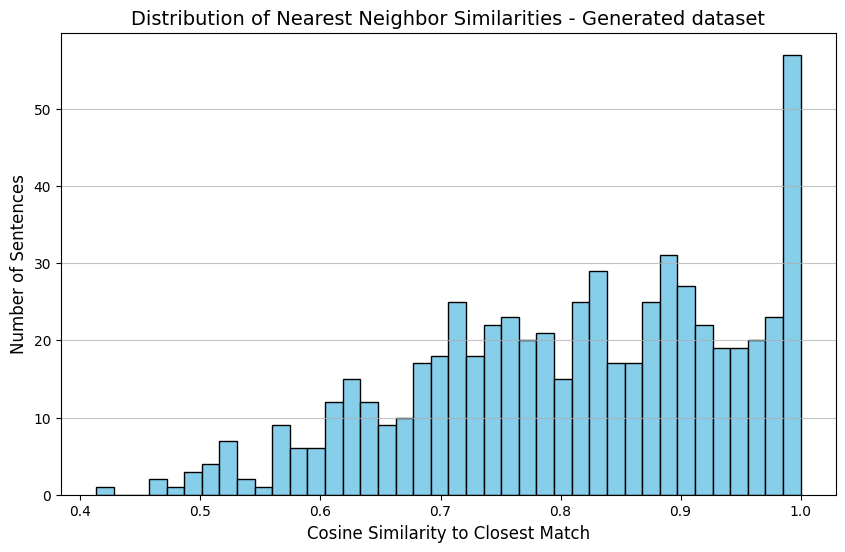

In [12]:
plt.figure(figsize=(10, 6))
plt.hist(max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities - Generated dataset", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()

In [2]:
fire_data_path = Path("data") / "02_processed" / "fire_train_processed.json"
fire_data = load_processed_data(fire_data_path)

fire_sentences = [sample.sentence for sample in fire_data]

_, fire_scores = evaluate_semantic_similarity(fire_sentences)

Using CUDA


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 656.67it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Before encoding
After encoding
Before double loop
After double loop
Before sorting
After sorting
Average Pairwise Similarity: 0.144

Most similar non identical sentences:
Pair 1 - Score: 0.900, idx1: 1917, idx2: 2113
  A: PricewaterhouseCoopers LLP , the independent registered public accounting firm that audited the financial statements included in this Annual Report on Form 10 - K , has also audited the effectiveness of internal control over financial reporting as of December 31 , 2012 as stated in their report that appears on the following page .
  B: The effectiveness of the Company s internal control over financial reporting as of December 31 , 2012 , has been audited by PricewaterhouseCoopers LLP , an independent registered public accounting firm , as stated in their report which appears herein .

Pair 2 - Score: 0.898, idx1: 2002, idx2: 2003
  A: Compared to 2011 : Off - system sales revenue decreased by $ 40.1 million , or 39 percent , in 2012 as compared to 2011 , as a result o

In [3]:
fire_scores.fill_diagonal_(-1)   # So it doesn't match with itself
fire_max_scores, _ = torch.max(fire_scores, dim=1)
fire_max_scores_list = fire_max_scores.tolist()

In [4]:
duplicates = sum(1 for score in fire_max_scores_list if score >= 0.98)
very_similar = sum(1 for score in fire_max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in fire_max_scores_list if score < 0.85)

print(f"Total Sentences: {len(fire_sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(fire_max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(fire_max_scores_list):.3f}")

Total Sentences: 2117
Exact/Near Duplicates (Score > 0.98): 19 sentences
Very Similar Sentences (Score 0.85-0.98): 99 sentences
Different Sentences (Score < 0.85): 1999 sentences
Avg. cosine similarity to closest match: 0.575
Median cosine similarity to closest match: 0.547


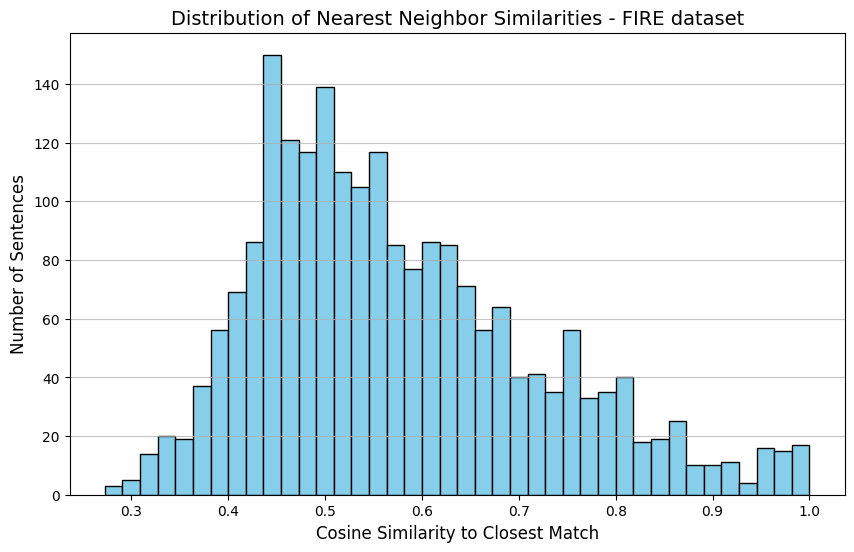

In [5]:
plt.figure(figsize=(10, 6))
plt.hist(fire_max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities - FIRE dataset", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()

In [14]:
elekta = Path("data") / "02_processed" / "elekta_processed.json"
elekta_data = load_processed_data(elekta)

elekta_sentences = [sample.sentence for sample in elekta_data]

_, elekta_scores = evaluate_semantic_similarity(elekta_sentences)

Using CUDA


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 675.42it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Average Pairwise Similarity: 0.167

Most similar non identical sentences:
Pair 1 - Score: 0.896, idx1: 1589, idx2: 1613
  A: Cash flow from operating activities in relation to EBITDA.
  B: The operational cash conversion shows the relation between cash flow from operating activities and EBITDA.

Pair 2 - Score: 0.896, idx1: 614, idx2: 615
  A: The operating cash flow (cash flow from operating activities exclusive of change in working capital) Cash flow from operating activities amounted to SEK 2,114 M (1,869), an increase of SEK 245 M compared with the previous year.
  B: Cash flow from operating activities increased to SEK 1,964 M (1,858).

Pair 3 - Score: 0.894, idx1: 454, idx2: 917
  A: The guidelines for remuneration to the executive management were adopted by the AGM 2020 and will apply until the AGM 2024 at the latest.
  B: The guidelines for remuneration to the executive management, adopted by the AGM in 2020, are presented on page 28.

Pair 4 - Score: 0.892, idx1: 348, idx2: 61

In [15]:
elekta_scores.fill_diagonal_(-1)   # So it doesn't match with itself
elekta_max_scores, _ = torch.max(elekta_scores, dim=1)
elekta_max_scores_list = elekta_max_scores.tolist()

In [16]:
duplicates = sum(1 for score in elekta_max_scores_list if score >= 0.98)
very_similar = sum(1 for score in elekta_max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in elekta_max_scores_list if score < 0.85)

print(f"Total Sentences: {len(elekta_sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(elekta_max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(elekta_max_scores_list):.3f}")

Total Sentences: 1976
Exact/Near Duplicates (Score > 0.98): 56 sentences
Very Similar Sentences (Score 0.85-0.98): 161 sentences
Different Sentences (Score < 0.85): 1759 sentences
Avg. cosine similarity to closest match: 0.700
Median cosine similarity to closest match: 0.696


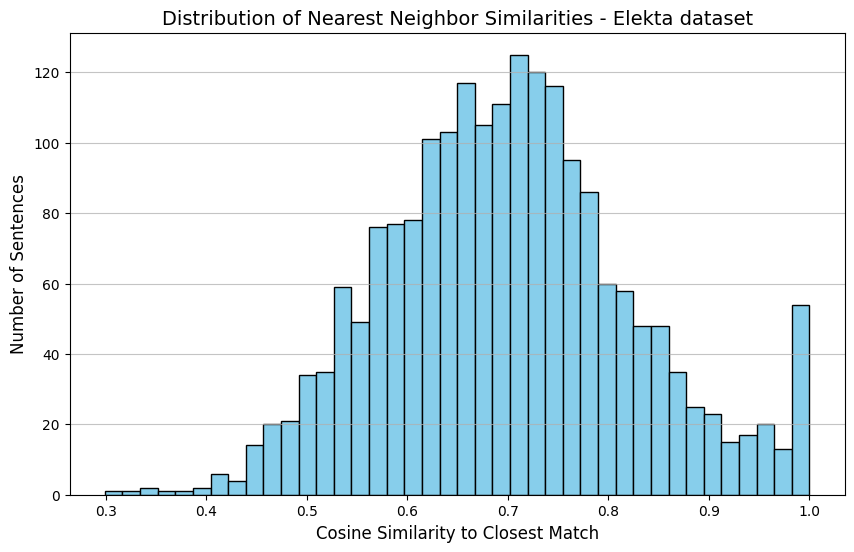

In [17]:
plt.figure(figsize=(10, 6))
plt.hist(elekta_max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities - Elekta dataset", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()

In [18]:
vestas = Path("data") / "02_processed" / "vestas_processed.json"
vestas_data = load_processed_data(vestas)

vestas_sentences = [sample.sentence for sample in vestas_data]

_, vestas_scores = evaluate_semantic_similarity(vestas_sentences)

Using CUDA


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 544.57it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Average Pairwise Similarity: 0.170

Most similar non identical sentences:
Pair 1 - Score: 0.899, idx1: 864, idx2: 878
  A: Using sector-specific country averages allows impact assessment across many suppliers based on assumptions of water use and pollution.
  B: Using sector-country averages allows impact assessment across many suppliers, but is based on assumptions of e.g., land use and air pollution levels.

Pair 2 - Score: 0.899, idx1: 149, idx2: 189
  A: 1 Market forecasts adapted from Wood Mackenzie: Global wind power market outlook update: Q 2024.
  B: 4 Adapted from Wood Mackenzie: Global wind power market outlook update: Q 2024.

Pair 3 - Score: 0.896, idx1: 1478, idx2: 1574
  A: Waste quantities are tracked through weight slips, invoices, or statements from the waste recipients and reported quarterly.
  B: The quantity of waste reported is based on weight slips, invoices or statements received from the waste recipients for deliveries included in the accounting period.

Pair 4 

In [19]:
vestas_scores.fill_diagonal_(-1)   # So it doesn't match with itself
vestas_max_scores, _ = torch.max(vestas_scores, dim=1)
vestas_max_scores_list = vestas_max_scores.tolist()

In [20]:
duplicates = sum(1 for score in vestas_max_scores_list if score >= 0.98)
very_similar = sum(1 for score in vestas_max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in vestas_max_scores_list if score < 0.85)

print(f"Total Sentences: {len(vestas_sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(vestas_max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(vestas_max_scores_list):.3f}")

Total Sentences: 3633
Exact/Near Duplicates (Score > 0.98): 121 sentences
Very Similar Sentences (Score 0.85-0.98): 231 sentences
Different Sentences (Score < 0.85): 3281 sentences
Avg. cosine similarity to closest match: 0.706
Median cosine similarity to closest match: 0.701


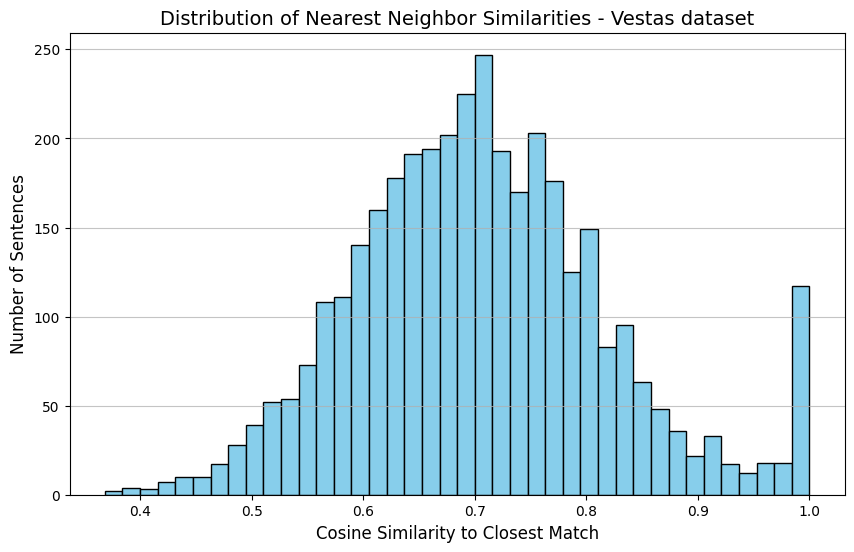

In [21]:
plt.figure(figsize=(10, 6))
plt.hist(vestas_max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities - Vestas dataset", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()

In [2]:
rebel = Path("data") / "02_processed" / "rebel_processed.json"
rebel_data = load_rebel_sample(rebel)

rebel_sentences = [sample.sentence for sample in rebel_data]

_, rebel_scores = evaluate_semantic_similarity(rebel_sentences)

Using CUDA


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 512.00it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Average Pairwise Similarity: 0.044

Most similar non-identical sentences:
Pair 1 - Score: 0.899, idx1: 1616, idx2: 5953
  A: It was listed on the National Register of Historic Places in 1983.
  B: The building was listed on the National Register of Historic Places in 1983.

Pair 2 - Score: 0.899, idx1: 1616, idx2: 6186
  A: It was listed on the National Register of Historic Places in 1983.
  B: It was added to the National Register of Historic Places on June 7, 1983.

Pair 3 - Score: 0.899, idx1: 159, idx2: 8171
  A: In 2014, the median household income in the USA was $53,700.
  B: By 2013, the median household income in the United States rose to $52,100.

Pair 4 - Score: 0.897, idx1: 2957, idx2: 4336
  A: The wingspan is 25–28 mm.
  B: The wingspan is about 47 mm.

Pair 5 - Score: 0.896, idx1: 6168, idx2: 9814
  A: The wingspan is 15–25 mm.
  B: The wingspan is about 40 mm.

Pair 6 - Score: 0.896, idx1: 1565, idx2: 6168
  A: The wingspan is about 32 mm.
  B: The wingspan is 15–25 mm.


In [3]:
rebel_scores.fill_diagonal_(-1)   # So it doesn't match with itself
rebel_max_scores, _ = torch.max(rebel_scores, dim=1)
rebel_max_scores_list = rebel_max_scores.tolist()

In [4]:
duplicates = sum(1 for score in rebel_max_scores_list if score >= 0.98)
very_similar = sum(1 for score in rebel_max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in rebel_max_scores_list if score < 0.85)

print(f"Total Sentences: {len(rebel_sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(rebel_max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(rebel_max_scores_list):.3f}")

Total Sentences: 10000
Exact/Near Duplicates (Score > 0.98): 39 sentences
Very Similar Sentences (Score 0.85-0.98): 126 sentences
Different Sentences (Score < 0.85): 9835 sentences
Avg. cosine similarity to closest match: 0.508
Median cosine similarity to closest match: 0.489


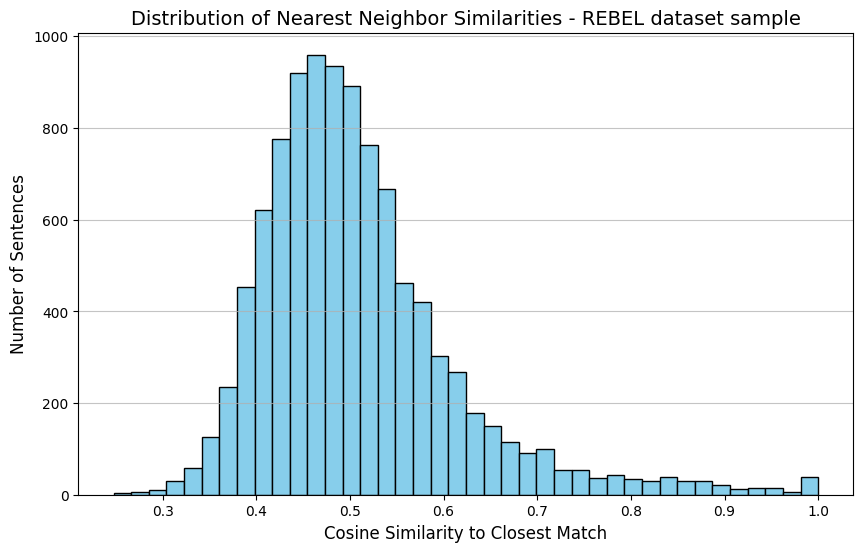

In [5]:
plt.figure(figsize=(10, 6))
plt.hist(rebel_max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities - REBEL dataset sample", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()

In [2]:
#synthetic_data_path = Path("data") / "03_synthetic" / "ontology_baseline_2_percent.json"
synthetic_data_path = Path("data") / "03_synthetic" / "ontology_2_percent_half_fixed_temp13.json"
#synthetic_data_path = Path("data") / "03_synthetic" / "few_shot_100_examples.json"
synthetic_data = load_synthetic_fire_data(synthetic_data_path)

sentences = [sample.sentence for sample in synthetic_data]

_, scores = evaluate_semantic_similarity(sentences)

Using CUDA
Average Pairwise Similarity: 0.287

Most similar non-identical sentences:
Pair 1 - Score: 0.896, idx1: 43, idx2: 70
  A: Apple's revenue has a value of $100 million, and they operate in the Technology sector.
  B: The revenue of Apple, a leader in the Technology sector, was $100 billion last year.

Pair 2 - Score: 0.882, idx1: 256, idx2: 273
  A: The company Tesla which is operating in the automotive sector has a product called the Model S with Elon Musk having the designation of CEO and the company's revenue increasing by 10 million dollars.
  B: Elon Musk is the CEO and an employee of Tesla, which produces the Model S, a product of the company, and the company's cash reserves have increased by $20 million.

Pair 3 - Score: 0.875, idx1: 145, idx2: 239
  A: Google will buy Fitbit for 2 billion dollars in 2020 with the expectation to increase its revenue with the new acquisition and become a leading company in the healthcare sector with Sundar Pichai being the CEO of Google, 

In [3]:
scores.fill_diagonal_(-1)   # So it doesn't match with itself
max_scores, _ = torch.max(scores, dim=1)
max_scores_list = max_scores.tolist()

In [4]:
duplicates = sum(1 for score in max_scores_list if score >= 0.98)
very_similar = sum(1 for score in max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in max_scores_list if score < 0.85)

print(f"Total Sentences: {len(sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(max_scores_list):.3f}")

Total Sentences: 351
Exact/Near Duplicates (Score > 0.98): 0 sentences
Very Similar Sentences (Score 0.85-0.98): 32 sentences
Different Sentences (Score < 0.85): 319 sentences
Avg. cosine similarity to closest match: 0.722
Median cosine similarity to closest match: 0.735


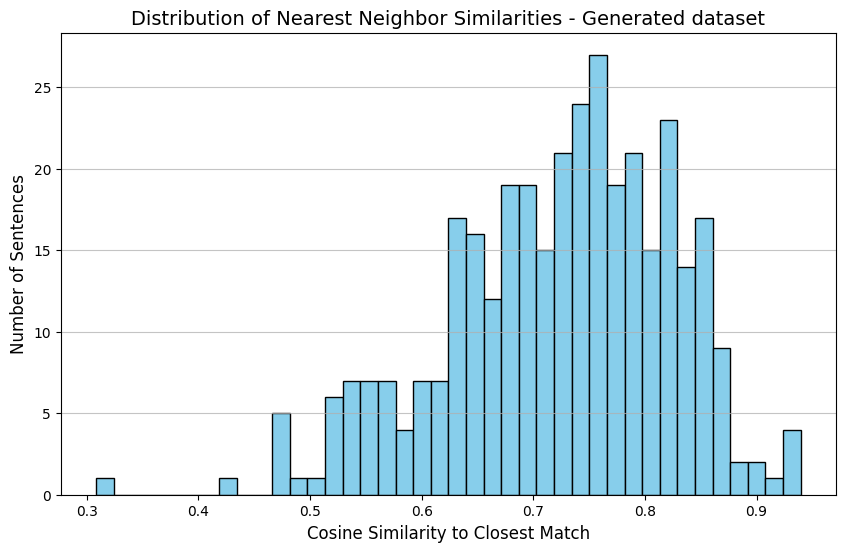

In [5]:
plt.figure(figsize=(10, 6))
plt.hist(max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities - Generated dataset", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()

In [10]:
synthetic_data_path = Path("data") / "03_synthetic" / "ontology_2_percent_half_fixed.json"
#synthetic_data_path = Path("data") / "03_synthetic" / "few_shot_100_examples.json"
synthetic_data = load_synthetic_fire_data(synthetic_data_path)

sentences = [sample.sentence for sample in synthetic_data]

_, scores = evaluate_semantic_similarity(sentences)

Using CUDA
Average Pairwise Similarity: 0.307

Most similar non-identical sentences:
Pair 1 - Score: 0.892, idx1: 66, idx2: 280
  A: Google is a subsidiary of Alphabet, and its CEO, Sundar Pichai, who is an employee of Google, has announced plans to acquire Fitbit, with this action happening in the second quarter of 2023, and Google's shares are now valued at $2500, increasing in value by $1000.
  B: Google, a company in the technology sector, acquired Fitbit, and the acquisition saw a value change increase of 1 billion dollars, with Sundar Pichai, the CEO of Google, holding the designation of CEO, and Fitbit's smartwatch, a product of Fitbit, became a subsidiary of Google, with Google's market value reaching 1.5 trillion dollars in 2022, a quantity of 1.5 trillion dollars in 2022.

Pair 2 - Score: 0.889, idx1: 0, idx2: 223
  A: The S&P 500 Index, which consists of 500 constituent companies, has a quantity of 500 stocks and is part of the finance sector, with a current value of $1.5 tr

In [11]:
scores.fill_diagonal_(-1)   # So it doesn't match with itself
max_scores, _ = torch.max(scores, dim=1)
max_scores_list = max_scores.tolist()

In [12]:
duplicates = sum(1 for score in max_scores_list if score >= 0.98)
very_similar = sum(1 for score in max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in max_scores_list if score < 0.85)

print(f"Total Sentences: {len(sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

print(f"Avg. cosine similarity to closest match: {statistics.mean(max_scores_list):.3f}")
print(f"Median cosine similarity to closest match: {statistics.median(max_scores_list):.3f}")

Total Sentences: 335
Exact/Near Duplicates (Score > 0.98): 0 sentences
Very Similar Sentences (Score 0.85-0.98): 36 sentences
Different Sentences (Score < 0.85): 299 sentences
Avg. cosine similarity to closest match: 0.741
Median cosine similarity to closest match: 0.748


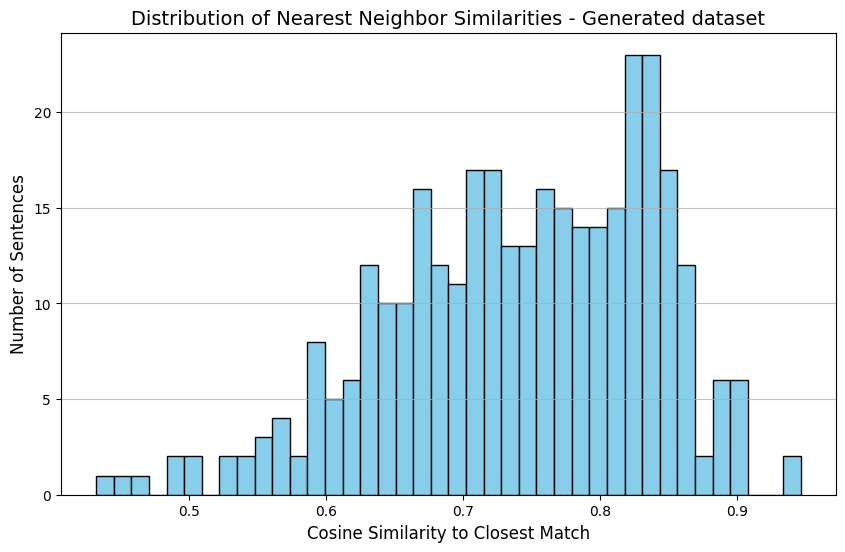

In [13]:
plt.figure(figsize=(10, 6))
plt.hist(max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities - Generated dataset", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()

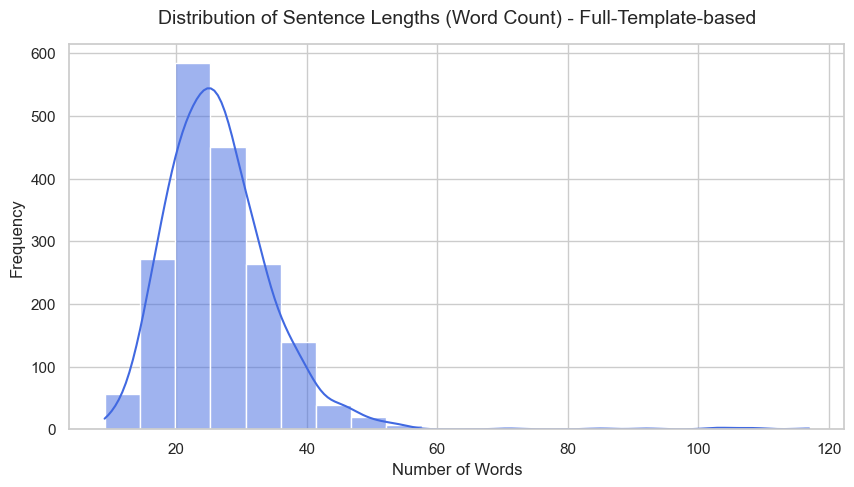

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

#synthetic_data_path = Path("data") / "02_processed" / "fire_train_processed.json"
#synthetic_data_path = Path("data") / "03_synthetic" / "few_shot_4_examples_temp_1_3.json"
#synthetic_data_path = Path("data") / "03_synthetic" / "ontology_2_percent_half_fixed_temp13.json"
synthetic_data_path = Path("data") / "03_synthetic" / "ontology_2_percent_all_fixed_temp13_schemas_long.json"

#synthetic_data = load_processed_fire_data(synthetic_data_path)
synthetic_data = load_synthetic_fire_data(synthetic_data_path)

# Set a clean visual style for the thesis
sns.set_theme(style="whitegrid")

# Extract the word count for each sentence
sentence_lengths = [len(sample.sentence.split()) for sample in synthetic_data]

# Plot the histogram
plt.figure(figsize=(10, 5))
sns.histplot(sentence_lengths, bins=20, kde=True, color="royalblue")

# Add labels and title
plt.title("Distribution of Sentence Lengths (Word Count) - Full-Template-based", fontsize=14, pad=15)
plt.xlabel("Number of Words", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.show()

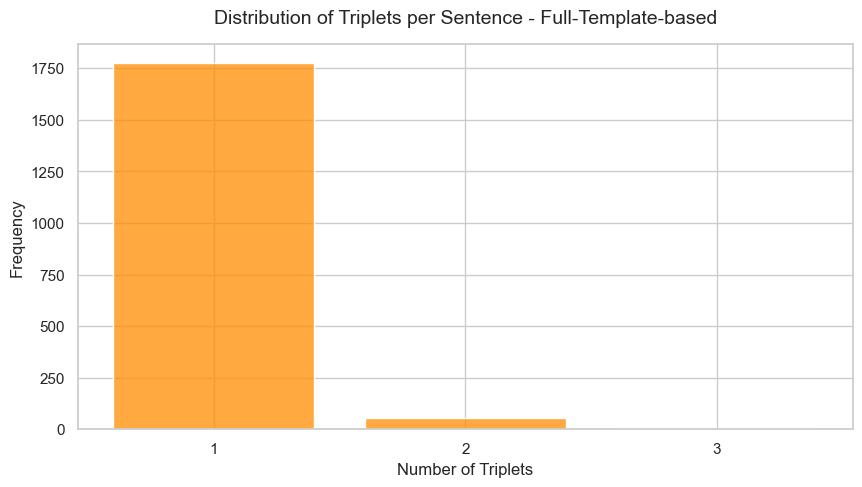

In [12]:
# Extract the number of triplets per sentence
triplet_counts = [len(sample.triplets) for sample in synthetic_data]

# Plot the discrete histogram
plt.figure(figsize=(10, 5))
sns.histplot(triplet_counts, discrete=True, shrink=0.8, color="darkorange")

# Add labels and title
plt.title("Distribution of Triplets per Sentence - Full-Template-based", fontsize=14, pad=15)
plt.xlabel("Number of Triplets", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

# Force the X-axis to only show whole numbers
min_triplets = min(triplet_counts)
max_triplets = max(triplet_counts)
plt.xticks(range(min_triplets, max_triplets + 1))

plt.show()